In [1]:
import numpy as np
from lib.dvr2d import *
from lib.utils import *
from lib.vqe import DVR_VQE
from lib.pot_gen import get_pot

import matplotlib.pyplot as plt
from matplotlib import rc

log_file = 'results/log.txt'

cmap = plt.get_cmap('tab10')
plt.rcParams["figure.figsize"] = (5,5)
plt.rcParams["font.size"] = 12
plt.rcParams["figure.dpi"] = 300
rc('text', usetex=True)
rc('font',**{'family':'serif','serif':['Computer Modern']})
%load_ext autoreload

In [2]:
mol_params = arhcl_params
pot_file = 'arhcl.txt'

dvr_options = {
    'type': 'jacobi',
    'N_R': 35, 
    'N_theta': 4,
    'l': 1,
    'K_max': 0,
    'r_min': 3.4,
    'r_max': 5, 
    'trunc': 0,
    'J': 0
}

vqe_options = {
    'optimizers': ['L_BFGS_B.8000'],
    # 'optimizers': ['COBYLA.100'],
    # 'repeats': 1, 
    'repeats': 5, 
    'beta': [1000 for i in range(10)],
    'seed': 42
}

ansatz_options = {
    'type': 'twolocal',
    'entanglement': 'opt',
    'gates': [4, 1],
    'reps': 1,
}


In [3]:
import qiskit
import qiskit_algorithms
import qiskit_aer

print(qiskit.__version__)
print(qiskit_algorithms.__version__)
print(qiskit_aer.__version__)

2.2.3
0.4.0
0.17.2


In [4]:
pot = get_pot(pot_file, take_cos=True)
dvr_vqe = DVR_VQE(mol_params, pot, log_dir='results/tests/')
# opt_params = dvr_vqe.get_dvr_vqe(dvr_options, ansatz_options, vqe_options, excited_states=True)

In [5]:
ansatz_options2 = {
    'type': 'twolocal',
    'entanglement': 'opt',
    'gates': [34, 31, 0, 17, 1, 28, 9, 10, 2],
    'reps': 4,
}

# opt_params2 = dvr_vqe.get_dvr_vqe(dvr_options, ansatz_options2, vqe_options, excited_states=True)

In [6]:
opt_params = []
energies = []
with np.load('results/excited_states/arhcl_twolocal_opt_1/vqe.npz', allow_pickle=True) as data:
    opt_params.append(*data['params'])
    energies.append(data['energies'])

for i in range(1, 11):
    with np.load(f'results/excited_states/arhcl_twolocal_opt_1/vqe_excited{i}.npz', allow_pickle=True) as data:
        opt_params.append(*data['params'])
        energies.append(data['energies'])

energies = np.array(energies).flatten()
opt_params = np.array(opt_params)
print(opt_params.shape)

opt_params2 = []
energies2 = []
with np.load('results/excited_states/arhcl_twolocal_opt_4/vqe.npz', allow_pickle=True) as data:
    opt_params2.append(*data['params'])
    energies2.append(data['energies'])

for i in range(1, 11):
    with np.load(f'results/excited_states/arhcl_twolocal_opt_4/vqe_excited{i}.npz', allow_pickle=True) as data:
        opt_params2.append(*data['params'])
        energies2.append(data['energies'])

energies2 = np.array(energies2).flatten()
opt_params2 = np.array(opt_params2)
print(opt_params2.shape)

(11, 8)
(11, 19)


In [7]:
h_dvr = dvr_vqe.get_h_dvr(dvr_options, J=0) * hartree

In [8]:
ansatz = dvr_vqe.get_ansatz(ansatz_options, 5)
ansatz2 = dvr_vqe.get_ansatz(ansatz_options2, 5)
print(ansatz)
print(ansatz2)

     ┌─────────────┐ ░            ░ ┌─────────────┐
q_0: ┤ Ry($x_{0}$) ├─░───■────────░─┤ Ry($x_{5}$) ├
     ├─────────────┤ ░   │        ░ ├─────────────┤
q_1: ┤ Ry($x_{1}$) ├─░───┼────■───░─┤ Ry($x_{6}$) ├
     ├─────────────┤ ░ ┌─┴─┐┌─┴─┐ ░ ├─────────────┤
q_2: ┤ Ry($x_{2}$) ├─░─┤ X ├┤ X ├─░─┤ Ry($x_{7}$) ├
     ├─────────────┤ ░ └───┘└───┘ ░ └─────────────┘
q_3: ┤ Ry($x_{3}$) ├─░────────────░────────────────
     ├─────────────┤ ░            ░                
q_4: ┤ Ry($x_{4}$) ├─░────────────░────────────────
     └─────────────┘ ░            ░                
     ┌─────────────┐ ░                      ░ ┌─────────────┐ ░       ░ »
q_0: ┤ Ry($x_{0}$) ├─░───■────■────■────────░─┤ Ry($x_{5}$) ├─░───■───░─»
     ├─────────────┤ ░ ┌─┴─┐  │    │        ░ ├─────────────┤ ░ ┌─┴─┐ ░ »
q_1: ┤ Ry($x_{1}$) ├─░─┤ X ├──┼────┼────────░─┤ Ry($x_{6}$) ├─░─┤ X ├─░─»
     ├─────────────┤ ░ └───┘┌─┴─┐  │        ░ ├─────────────┤ ░ └───┘ ░ »
q_2: ┤ Ry($x_{2}$) ├─░──────┤ X ├──┼────────░─┤ Ry($x_{7}$

In [9]:
circs = []
for i in range(11):
    circ = ansatz.assign_parameters(opt_params[i], inplace=False)
    circs.append(circ)

print(circs[0])

     ┌─────────────┐  ░            ░ ┌─────────────┐
q_0: ┤ Ry(-3.8657) ├──░───■────────░─┤ Ry(-4.7834) ├
     ├─────────────┤  ░   │        ░ ├─────────────┤
q_1: ┤ Ry(-1.7239) ├──░───┼────■───░─┤ Ry(-1.6626) ├
     ├─────────────┴┐ ░ ┌─┴─┐┌─┴─┐ ░ └┬────────────┤
q_2: ┤ Ry(-0.18914) ├─░─┤ X ├┤ X ├─░──┤ Ry(4.6131) ├
     ├─────────────┬┘ ░ └───┘└───┘ ░  └────────────┘
q_3: ┤ Ry(-2.0703) ├──░────────────░────────────────
     ├─────────────┤  ░            ░                
q_4: ┤ Ry(-3.6155) ├──░────────────░────────────────
     └─────────────┘  ░            ░                


In [10]:
circs2 = []
for i in range(11):
    circ = ansatz2.assign_parameters(opt_params2[i], inplace=False)
    circs2.append(circ)

print(circs2[0])

     ┌─────────────┐ ░                      ░ ┌──────────────┐ ░       ░ »
q_0: ┤ Ry(0.17691) ├─░───■────■────■────────░─┤ Ry(-0.90771) ├─░───■───░─»
     ├─────────────┤ ░ ┌─┴─┐  │    │        ░ ├──────────────┤ ░ ┌─┴─┐ ░ »
q_1: ┤ Ry(-3.9621) ├─░─┤ X ├──┼────┼────────░─┤ Ry(-0.60697) ├─░─┤ X ├─░─»
     ├─────────────┤ ░ └───┘┌─┴─┐  │        ░ └┬────────────┬┘ ░ └───┘ ░ »
q_2: ┤ Ry(-3.3973) ├─░──────┤ X ├──┼────────░──┤ Ry(3.3545) ├──░───■───░─»
     ├─────────────┤ ░      └───┘┌─┴─┐      ░  ├────────────┤  ░ ┌─┴─┐ ░ »
q_3: ┤ Ry(-6.1835) ├─░───────────┤ X ├──■───░──┤ Ry(6.0701) ├──░─┤ X ├─░─»
     └┬────────────┤ ░           └───┘┌─┴─┐ ░  ├────────────┤  ░ └───┘ ░ »
q_4: ─┤ Ry(1.3123) ├─░────────────────┤ X ├─░──┤ Ry(0.3293) ├──░───────░─»
      └────────────┘ ░                └───┘ ░  └────────────┘  ░       ░ »
«      ┌────────────┐  ░       ░                 ░            ░ ┌─────────────┐
«q_0: ─┤ Ry(3.3253) ├──░───────░─────────────────░───■────────░─┤ Ry(-4.9117) ├
«      ├───────

In [11]:
from qiskit.quantum_info import Statevector

sv1s = np.array([Statevector.from_instruction(circ) for circ in circs])
sv2s = np.array([Statevector.from_instruction(circ) for circ in circs2])

In [12]:
h_dvr = dvr_vqe.get_h_dvr(dvr_options, J=0) * hartree
e_vals, e_vecs = np.linalg.eigh(h_dvr)
print(e_vals)



[-1.15177966e+02 -9.09589843e+01 -8.27269329e+01 -6.30933095e+01
 -5.66353299e+01 -4.61873465e+01 -3.66289871e+01 -3.23994567e+01
 -1.98380374e+01 -1.12446448e+01  3.46790215e-01  4.95242117e+00
  1.69875756e+01  2.54423614e+01  3.13644105e+01  5.25875721e+01
  5.51273597e+01  6.15700203e+01  7.62069229e+01  8.08985533e+01
  9.87731453e+01  1.21103588e+02  1.30381303e+02  1.87604716e+02
  2.21060197e+02  2.53080460e+02  3.08072445e+02  3.64812347e+02
  6.84855183e+02  7.31963034e+02  7.97695731e+02  8.48116444e+02]


In [13]:
print(sv1s[0].conj().T @ h_dvr @ sv1s[0])

(-114.64454395866343+0j)


In [14]:
fid1s = []
for i in range(10):
    fid1 = np.abs(np.dot(sv1s[i], e_vecs[:,i].conj()))**2
    fid1s.append(fid1)
    print(f'Fidelity VQE 1 state {i}: {fid1}')
print('----')
fid2s = []
for i in range(10):
    fid2 = np.abs(np.dot(sv2s[i], e_vecs[:,i].conj()))**2
    fid2s.append(fid2)
    print(f'Fidelity VQE 2 state {i}: {fid2}')

Fidelity VQE 1 state 0: 0.9924366316819907
Fidelity VQE 1 state 1: 0.7856099532264458
Fidelity VQE 1 state 2: 0.734496869652291
Fidelity VQE 1 state 3: 0.001133416548190469
Fidelity VQE 1 state 4: 8.55088814433893e-06
Fidelity VQE 1 state 5: 0.4674450580842338
Fidelity VQE 1 state 6: 0.07212064992353885
Fidelity VQE 1 state 7: 0.37072570272687416
Fidelity VQE 1 state 8: 0.0030914416206394148
Fidelity VQE 1 state 9: 0.11766689602210453
----
Fidelity VQE 2 state 0: 0.9998903056106214
Fidelity VQE 2 state 1: 0.9597357112165861
Fidelity VQE 2 state 2: 0.9602884131135273
Fidelity VQE 2 state 3: 0.9911703488969761
Fidelity VQE 2 state 4: 0.9886561970150267
Fidelity VQE 2 state 5: 0.9112476700453275
Fidelity VQE 2 state 6: 0.8710052880003021
Fidelity VQE 2 state 7: 0.9182528061469525
Fidelity VQE 2 state 8: 0.6738421330395981
Fidelity VQE 2 state 9: 0.6640530931730194


c:\Users\kasna\anaconda3\lib\site-packages\matplotlib\cbook\__init__.py:1335: ComplexWarning: Casting complex values to real discards the imaginary part
  return np.asarray(x, float)


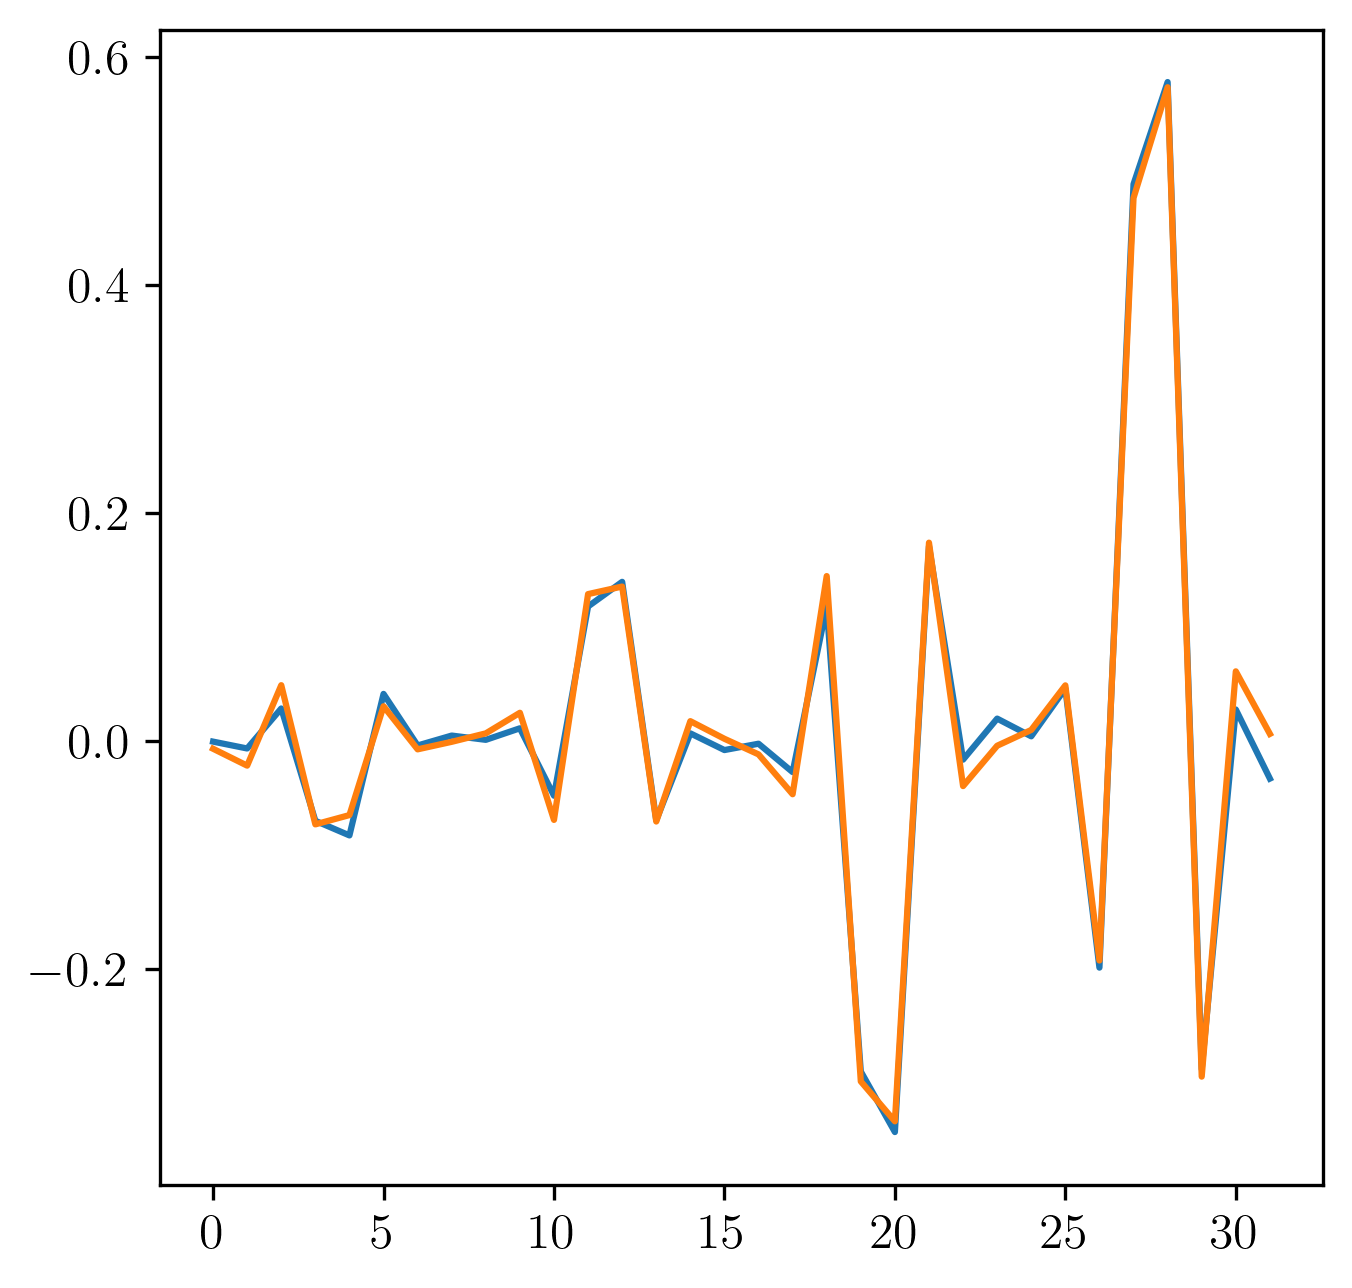

In [15]:
plt.plot(sv1s[0])
plt.plot(e_vecs[:,0])

Text(0, 0.5, 'Energy (cm$^{-1}$)')

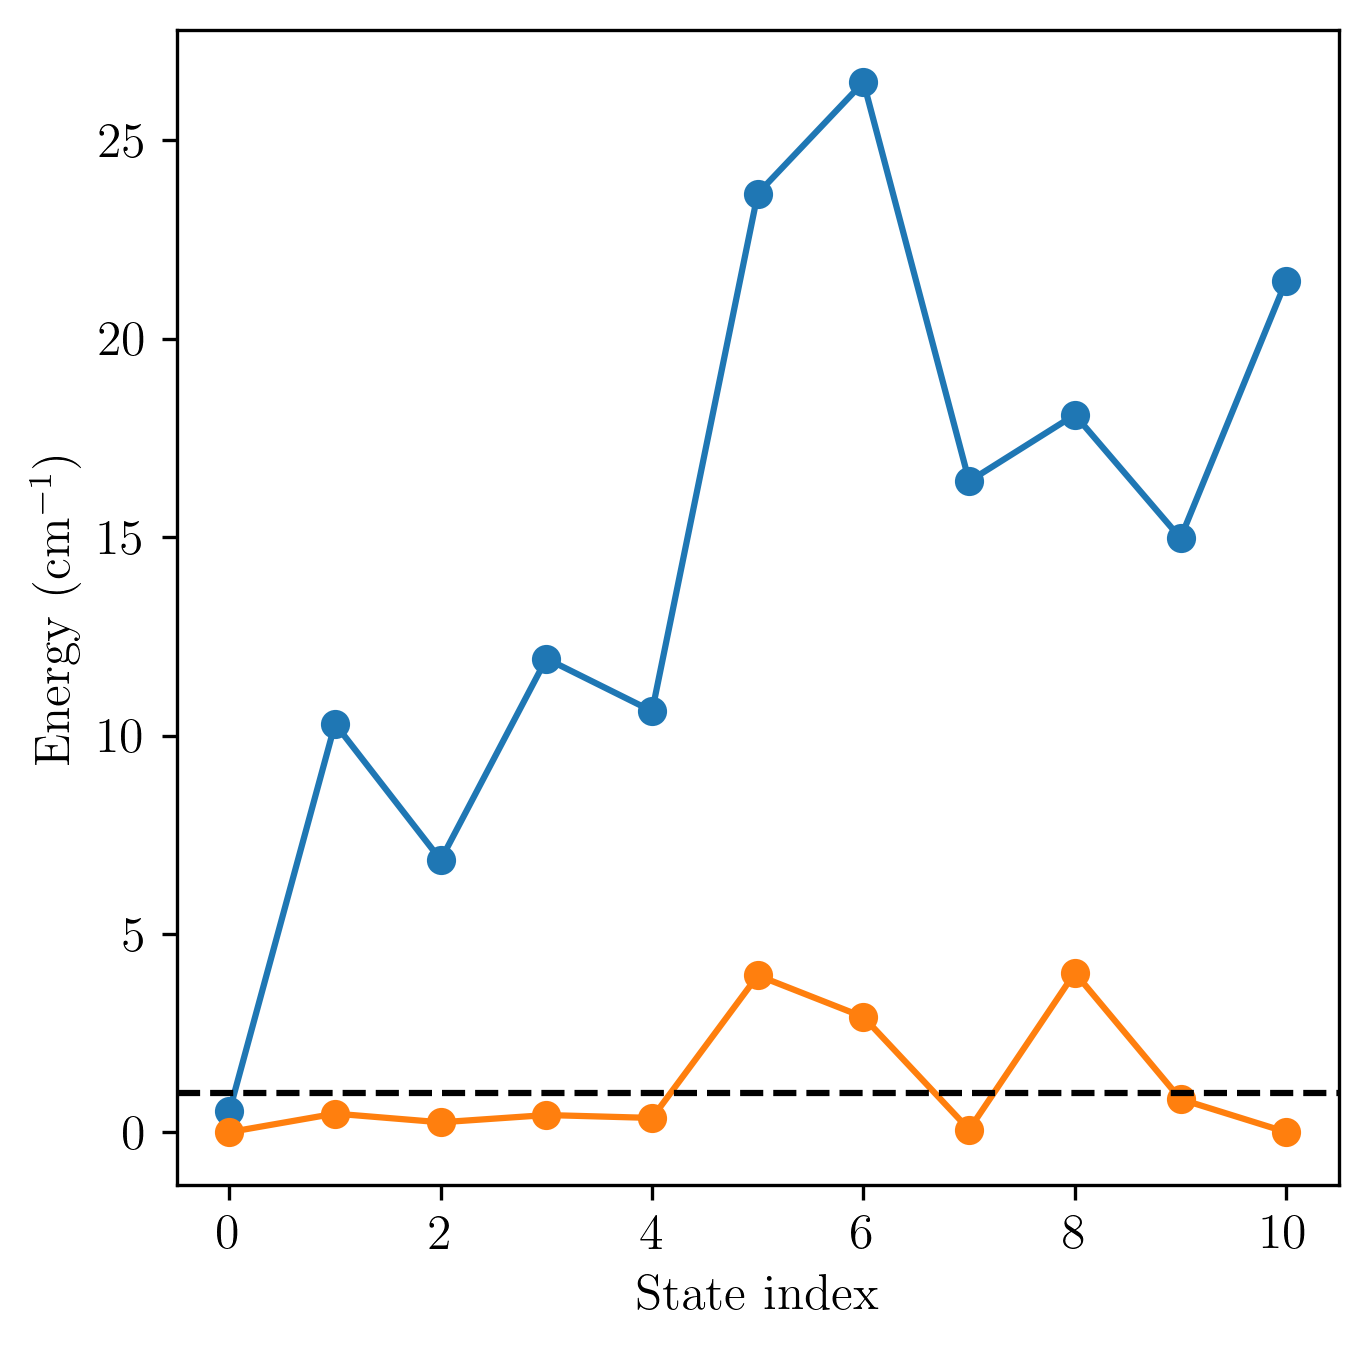

In [16]:
plt.plot(np.abs(energies - e_vals[:11]), 'o-', label='VQE $\\mathcal{C}_1$')
plt.plot(np.abs(energies2 - e_vals[:11]), 'o-', label='VQE $\\mathcal{C}_{0.01}$')
# plt.plot(e_vals[:11], 'x--', label='Exact DVR')
plt.axhline(1, color='black', linestyle='--')
plt.xlabel('State index')
plt.ylabel('Energy (cm$^{-1}$)')  

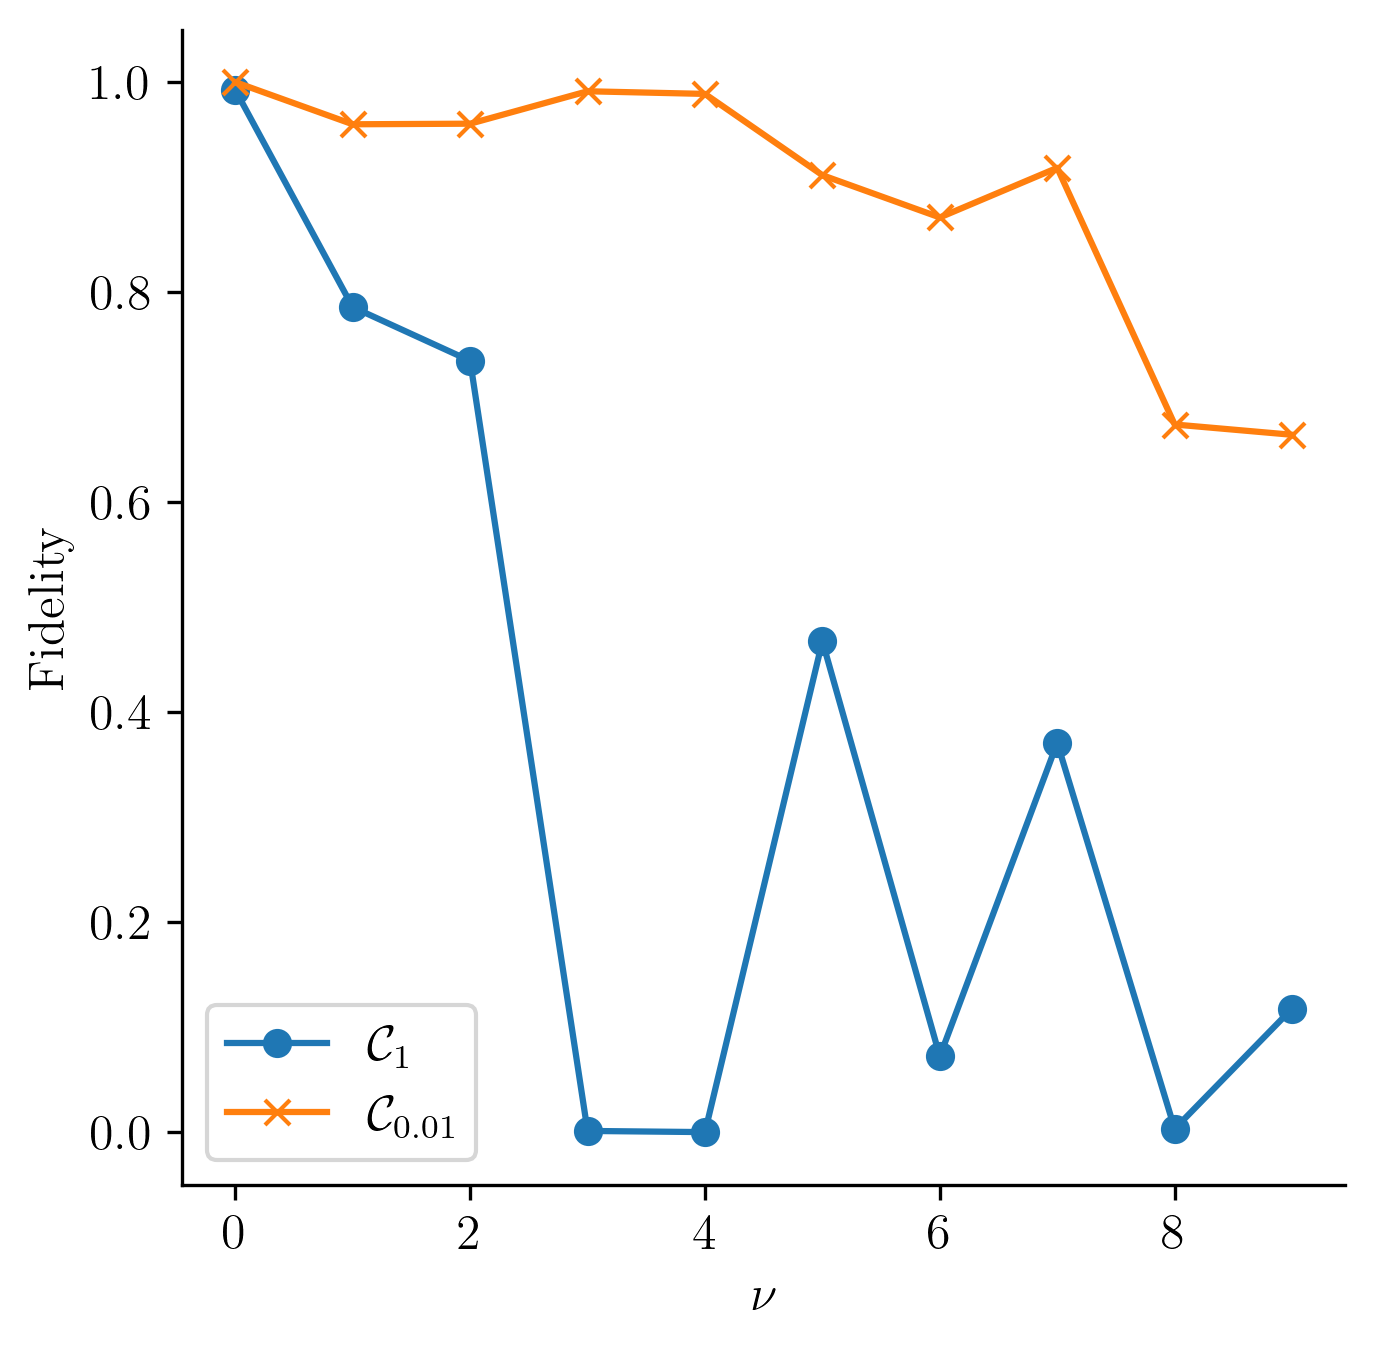

In [19]:
plt.rcParams["figure.figsize"] = (5,5)
plt.rcParams["font.size"] = 12
plt.rcParams["figure.dpi"] = 300

ax = plt.subplot()
ax.plot(fid1s, 'o-', label='$\\mathcal{C}_1$')
ax.plot(fid2s, 'x-', label='$\\mathcal{C}_{0.01}$')
ax.spines.right.set_visible(False)
ax.spines.top.set_visible(False)
ax.set_xlabel('$\\nu$')
ax.set_ylabel('Fidelity')
ax.legend()
plt.savefig('figs/arhcl_fidelity.pdf', bbox_inches='tight')